In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from loader import OUTPUT_DIR, MODEL_ORDER, MODEL_COLORS

df = pd.read_csv(OUTPUT_DIR / "loss_by_turn_progress.csv")
df

,model,turn_progress_bin,brier_mean,brier_std,log_loss_mean,log_loss_std,n_samples
0,naive,0.0-0.1,0.109411,0.000002,0.376929,0.000009,188312
1,naive,0.1-0.2,0.109411,0.000002,0.376929,0.000009,186176
2,naive,0.2-0.3,0.109411,0.000002,0.376929,0.000009,187088
3,naive,0.3-0.4,0.109411,0.000002,0.376929,0.000009,186632
4,naive,0.4-0.5,0.109411,0.000002,0.376929,0.000009,186624
...,...,...,...,...,...,...,...
75,attention_mlp,0.5-0.6,0.079726,0.002594,0.254949,0.007676,188776
76,attention_mlp,0.6-0.7,0.072275,0.004518,0.229145,0.013604,187360
77,attention_mlp,0.7-0.8,0.062172,0.007674,0.195484,0.021477,186856
78,attention_mlp,0.8-0.9,0.048960,0.007267,0.154191,0.019446,187624


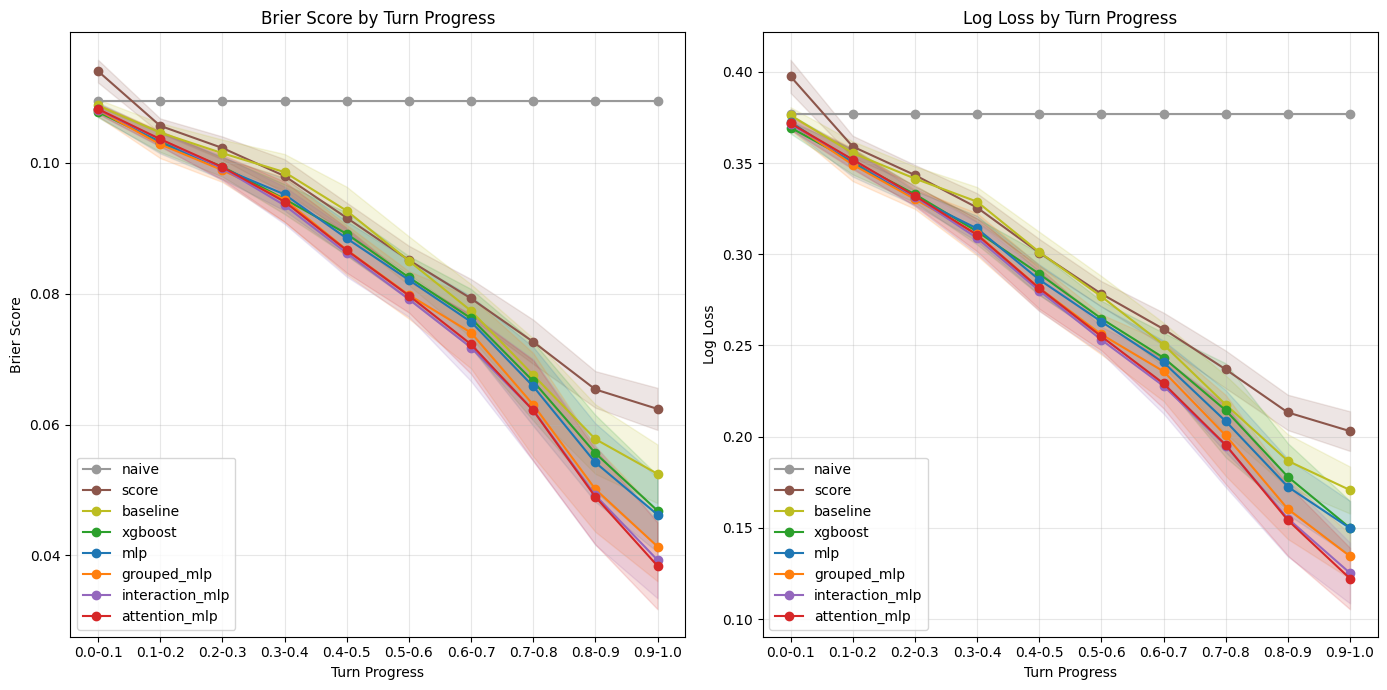

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for name in MODEL_ORDER:
    grp = df[df["model"] == name]
    if grp.empty:
        continue
    color = MODEL_COLORS[name]
    axes[0].plot(grp["turn_progress_bin"], grp["brier_mean"], marker="o", label=name, color=color)
    axes[0].fill_between(
        grp["turn_progress_bin"],
        grp["brier_mean"] - grp["brier_std"],
        grp["brier_mean"] + grp["brier_std"],
        alpha=0.15, color=color,
    )

axes[0].set_xlabel("Turn Progress")
axes[0].set_ylabel("Brier Score")
axes[0].set_title("Brier Score by Turn Progress")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for name in MODEL_ORDER:
    grp = df[df["model"] == name]
    if grp.empty:
        continue
    color = MODEL_COLORS[name]
    axes[1].plot(grp["turn_progress_bin"], grp["log_loss_mean"], marker="o", label=name, color=color)
    axes[1].fill_between(
        grp["turn_progress_bin"],
        grp["log_loss_mean"] - grp["log_loss_std"],
        grp["log_loss_mean"] + grp["log_loss_std"],
        alpha=0.15, color=color,
    )

axes[1].set_xlabel("Turn Progress")
axes[1].set_ylabel("Log Loss")
axes[1].set_title("Log Loss by Turn Progress")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()